# Assignment 2, Section B: Robust CIFAR-10 classification with only 500 training images
**Course:** Deep Learning for Perception, Fall 2026

**Goal.** Train a network from scratch (no pretrained weights, at most 1,000,000 parameters, with an Inception-style module) on 400 training images, tune on 100 validation images, and test on a corrupted version of the CIFAR-10 test set.

**How this notebook is organised**

| Part | What happens |
|---|---|
| Setup | data, 400/100 split, corrupted test set, model, augmentation tools |
| A | Baseline with no augmentation, learning curves, diagnosis |
| B | Augmentation design, plus answers to the three questions |
| C | Regularization, validation-only hyper-parameter selection |
| D | Ablation table, mean ± std over 3 seeds |
| E | Per-class accuracy, confusion matrix, misclassified images, hidden-corruption test |
| F | Test-time augmentation (bonus) |

**Rules followed.** Train from scratch. 3 seeds (0, 1, 2) and at most 60 epochs. Every hyper-parameter is chosen on the 100-image validation split only. Test sets are evaluated only after training has finished, never inside a decision loop. Augmentation runs on the fly, per mini-batch, on training data only. No augmented copies are saved.

**Note on the shifted test set.** The official `shifted_test` file was not supplied with the assignment text, so this notebook rebuilds one with a fixed seed following the description: rotation up to ±25°, brightness/contrast change, blur, noise, about 25% occlusion, plus one extra hidden corruption (which I chose, see Setup). If you have the official file, set `OFFICIAL_SHIFTED_PATH` in the first code cell and the notebook will use it.

In [2]:
import os, time, json, math, random, copy, itertools, warnings
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ---------------- global settings ----------------
SEEDS        = [0, 1, 2]     # the 3 training seeds
SPLIT_SEED   = 42            # fixes train_small (500 imgs) and the 400/100 split
SHIFT_SEED   = 1234          # fixes the corruption pipeline of shifted_test
EPOCHS       = 60            # maximum epochs (assignment limit)
BATCH_SIZE   = 50
NUM_CLASSES  = 10
OFFICIAL_SHIFTED_PATH = None # optional: path to an official .npz/.pt shifted test file
OUT_DIR = "results"; os.makedirs(OUT_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    torch.set_num_threads(max(1, os.cpu_count() or 1))

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.use_deterministic_algorithms(True, warn_only=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
CLASSES = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
print("device:", device, "| torch", torch.__version__, "| seeds", SEEDS, "| max epochs", EPOCHS)

device: cuda | torch 2.11.0+cu130 | seeds [0, 1, 2] | max epochs 60
device: cuda | torch 2.11.0+cu130 | seeds [0, 1, 2] | max epochs 60


In [3]:
def load_cifar10():
    # uses a cached cifar10.npz if present, otherwise downloads with torchvision (then caches)
    if os.path.exists("cifar10.npz"):
        d = np.load("cifar10.npz")
        return d["x_train"], d["y_train"], d["x_test"], d["y_test"]
    from torchvision.datasets import CIFAR10
    tr = CIFAR10("./data", train=True, download=True); te = CIFAR10("./data", train=False, download=True)
    xtr, ytr = tr.data, np.array(tr.targets); xte, yte = te.data, np.array(te.targets)
    np.savez_compressed("cifar10.npz", x_train=xtr, y_train=ytr, x_test=xte, y_test=yte)
    return xtr, ytr, xte, yte

x_train_full, y_train_full, x_test_np, y_test_np = load_cifar10()
print("full train", x_train_full.shape, "| test", x_test_np.shape)

# ---- train_small: 50 images per class (fixed seed), then 400 train / 100 validation (stratified) ----
rng = np.random.RandomState(SPLIT_SEED)
tr_idx, va_idx = [], []
for c in range(NUM_CLASSES):
    idx = rng.permutation(np.where(y_train_full == c)[0])[:50]    # 50 per class -> 500 total
    tr_idx += list(idx[:40]); va_idx += list(idx[40:])            # 40 train + 10 val per class
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)

def to_t(x):  # uint8 NHWC -> float NCHW in [0,1]
    return torch.from_numpy(x).permute(0, 3, 1, 2).float().div(255.0).contiguous()

Xtr, Ytr = to_t(x_train_full[tr_idx]), torch.from_numpy(y_train_full[tr_idx])
Xva, Yva = to_t(x_train_full[va_idx]), torch.from_numpy(y_train_full[va_idx])
Xclean, Yclean = to_t(x_test_np), torch.from_numpy(y_test_np)
print("train", tuple(Xtr.shape), np.bincount(Ytr.numpy()), "\nval  ", tuple(Xva.shape), np.bincount(Yva.numpy()))

# channel statistics from the 400 training images only
MEAN = Xtr.mean((0, 2, 3)).view(1, 3, 1, 1); STD = Xtr.std((0, 2, 3)).view(1, 3, 1, 1)
print("mean", MEAN.flatten().numpy().round(3), "std", STD.flatten().numpy().round(3))

100%|██████████| 170M/170M [26:40<00:00, 107kB/s]


full train (50000, 32, 32, 3) | test (10000, 32, 32, 3)
train (400, 3, 32, 32) [40 40 40 40 40 40 40 40 40 40] 
val   (100, 3, 32, 32) [10 10 10 10 10 10 10 10 10 10]
mean [0.489 0.485 0.456] std [0.253 0.246 0.264]


## Setup: the corrupted (shifted) test set
The pipeline below is applied **once**, with a fixed seed, to the 10,000 CIFAR-10 test images. For every image the corruption parameters are stored, which is used later for error analysis.

| Step | Detail |
|---|---|
| Rotation | uniform in ±25° (black corners) |
| Brightness / contrast | brightness factor in [0.5, 1.5], contrast factor in [0.6, 1.4] |
| Blur | 5×5 Gaussian (σ = 1), applied to 30% of the images |
| Noise | Gaussian, σ = 0.08, on 30% of the images |
| **Hidden corruption** | random permutation of the RGB channels (channel swap) on 50% of the images |
| Occlusion | one rectangle covering about 25% of the image (20–30%), random colour |

The hidden corruption is only an example of the kind of thing the assignment mentions. Training code never calls these functions, it has its own augmentations.

shifted test built in 3.5s | channel-swapped images: 49.9% | mean occlusion 25.0%


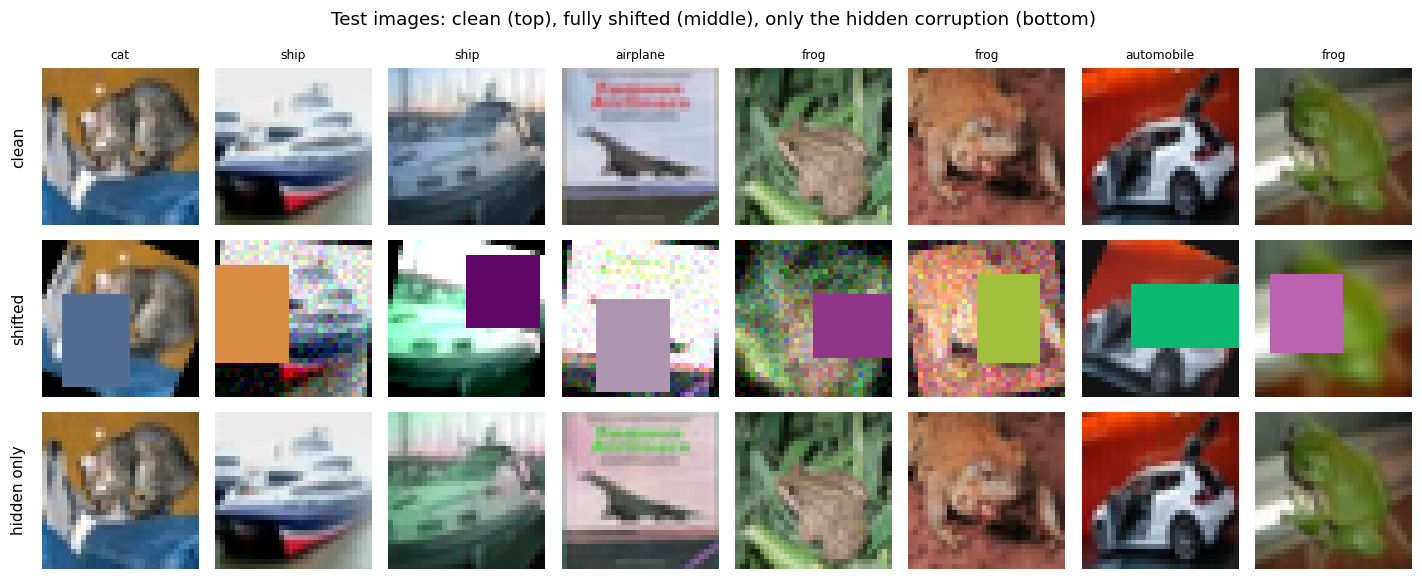

In [4]:
def gaussian_kernel(k=5, sigma=1.0):
    ax = torch.arange(k).float() - (k - 1) / 2
    g = torch.exp(-(ax ** 2) / (2 * sigma ** 2)); g = g / g.sum()
    return (g[:, None] * g[None, :]).view(1, 1, k, k)

def blur_batch(x, sigma=1.0, k=5):
    w = gaussian_kernel(k, sigma).to(x.device).repeat(3, 1, 1, 1)
    return F.conv2d(F.pad(x, (k // 2,) * 4, mode="reflect"), w, groups=3)

def affine_batch(x, angle_rad, scale, tx, ty, flip):
    # all arguments are per-sample tensors on the same device as x; tx, ty are in normalized units (1 px = 2/32)
    c, s = torch.cos(angle_rad) / scale, torch.sin(angle_rad) / scale
    theta = torch.zeros(x.size(0), 2, 3, device=x.device)
    theta[:, 0, 0] = c * flip; theta[:, 0, 1] = -s; theta[:, 0, 2] = tx
    theta[:, 1, 0] = s * flip; theta[:, 1, 1] = c;  theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)

def rect_mask(n, H, W, top, left, h, w, dev):
    ys = torch.arange(H, device=dev).view(1, H, 1); xs = torch.arange(W, device=dev).view(1, 1, W)
    t, l, hh, ww = [v.view(-1, 1, 1) for v in (top, left, h, w)]
    return ((ys >= t) & (ys < t + hh) & (xs >= l) & (xs < l + ww)).unsqueeze(1)

PERMS = torch.tensor([[0,2,1],[1,0,2],[1,2,0],[2,0,1],[2,1,0]])   # non-identity channel permutations

def make_shifted(x, seed=SHIFT_SEED, steps=("rot","photo","blur","noise","hidden","occ")):
    # Deterministic corruption pipeline. All random draws are made for every image, so using a subset of
    # `steps` (e.g. only the hidden corruption) keeps exactly the same per-image parameters.
    g = torch.Generator().manual_seed(seed); n, _, H, W = x.shape
    R = lambda *s: torch.rand(*s, generator=g)
    ang = (R(n) * 2 - 1) * 25.0
    bri, con = 0.5 + R(n), 0.6 + 0.8 * R(n)
    blur_m, noise_m = R(n) < 0.3, R(n) < 0.3
    hid_m, hid_k = R(n) < 0.5, (R(n) * 5).long().clamp(max=4)
    area, aspect = 0.20 + 0.10 * R(n), 0.6 + R(n)
    top_r, left_r, col = R(n), R(n), R(n, 3)
    eps = torch.randn(x.shape, generator=g) * 0.08
    out = x.clone()
    if "rot" in steps:
        z = torch.zeros(n)
        out = affine_batch(out, ang * math.pi / 180, torch.ones(n), z, z, torch.ones(n))
    if "photo" in steps:
        m = out.mean((1, 2, 3), keepdim=True)
        out = ((out - m) * con.view(-1,1,1,1) + m) * bri.view(-1,1,1,1)
        out = out.clamp(0, 1)
    if "blur" in steps:
        out = torch.where(blur_m.view(-1,1,1,1), blur_batch(out), out)
    if "noise" in steps:
        out = torch.where(noise_m.view(-1,1,1,1), (out + eps).clamp(0, 1), out)
    if "hidden" in steps:
        for k in range(5):
            sel = hid_m & (hid_k == k)
            if sel.any(): out[sel] = out[sel][:, PERMS[k]]
    if "occ" in steps:
        h = torch.sqrt(area * H * W * aspect).round().clamp(4, H).long()
        w = (area * H * W / h.float()).round().clamp(4, W).long()
        top = (top_r * (H - h + 1).float()).floor().long(); left = (left_r * (W - w + 1).float()).floor().long()
        out = torch.where(rect_mask(n, H, W, top, left, h, w, out.device), col.view(n, 3, 1, 1), out)
    meta = dict(angle=ang.numpy(), bright=bri.numpy(), contrast=con.numpy(), blur=blur_m.numpy(),
                noise=noise_m.numpy(), swapped=hid_m.numpy(), occ_area=(h*w).float().numpy()/(H*W) if "occ" in steps else None)
    return out.clamp(0, 1), meta

t0 = time.time()
if OFFICIAL_SHIFTED_PATH:
    d = torch.load(OFFICIAL_SHIFTED_PATH) if OFFICIAL_SHIFTED_PATH.endswith(".pt") else np.load(OFFICIAL_SHIFTED_PATH)
    Xshift, Yshift, shift_meta = to_t(np.asarray(d["x"])) if not torch.is_tensor(d["x"]) else d["x"], Yclean, None
else:
    Xshift, shift_meta = make_shifted(Xclean); Yshift = Yclean
Xhidden_only, _ = make_shifted(Xclean, steps=("hidden",))   # ONLY the hidden corruption on the clean test set (Part E.4)
print(f"shifted test built in {time.time()-t0:.1f}s | channel-swapped images: {shift_meta['swapped'].mean():.1%} | mean occlusion {shift_meta['occ_area'].mean():.1%}")

fig, ax = plt.subplots(3, 8, figsize=(13, 5.4))
for j in range(8):
    ax[0, j].imshow(Xclean[j].permute(1, 2, 0)); ax[1, j].imshow(Xshift[j].permute(1, 2, 0)); ax[2, j].imshow(Xhidden_only[j].permute(1, 2, 0))
    ax[0, j].set_title(CLASSES[Yclean[j]], fontsize=8)
    for r in range(3): ax[r, j].axis("off")
ax[0, 0].text(-0.1, 0.5, "clean", transform=ax[0, 0].transAxes, rotation=90, va="center", ha="right")
ax[1, 0].text(-0.1, 0.5, "shifted", transform=ax[1, 0].transAxes, rotation=90, va="center", ha="right")
ax[2, 0].text(-0.1, 0.5, "hidden only", transform=ax[2, 0].transAxes, rotation=90, va="center", ha="right")
fig.suptitle("Test images: clean (top), fully shifted (middle), only the hidden corruption (bottom)")
plt.tight_layout(); plt.show()

## Model
An AlexNet/LeNet-style stem (one 5×5 convolution with max pooling) is followed by **three Inception modules** (parallel 1×1, 3×3 and 5×5 branches, each of the 3×3/5×5 branches preceded by a 1×1 reduction, plus a pooling branch with 1×1 projection). Max pooling sits between the modules, and a Global Average Pooling layer replaces the large fully connected layers, with Dropout before the single linear classifier.
Every convolution is followed by BatchNorm and ReLU.

In [5]:
class CBR(nn.Sequential):
    def __init__(self, cin, cout, k, p=0):
        super().__init__(nn.Conv2d(cin, cout, k, padding=p, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Inception(nn.Module):
    # branches: 1x1 | 1x1 reduce -> 3x3 | 1x1 reduce -> 5x5 | 3x3 maxpool -> 1x1 projection
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = CBR(cin, c1, 1)
        self.b3 = nn.Sequential(CBR(cin, c3r, 1), CBR(c3r, c3, 3, 1))
        self.b5 = nn.Sequential(CBR(cin, c5r, 1), CBR(c5r, c5, 5, 2))
        self.bp = nn.Sequential(nn.MaxPool2d(3, 1, 1), CBR(cin, cp, 1))
        self.cout = c1 + c3 + c5 + cp
    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], 1)

class Net(nn.Module):
    def __init__(self, drop=0.3, nc=NUM_CLASSES):
        super().__init__()
        self.stem = nn.Sequential(CBR(3, 32, 5, 2), nn.MaxPool2d(2))                 # 32x32 -> 16x16
        self.inc1 = Inception(32, 16, 16, 24, 4, 8, 8)                              # -> 56 ch
        self.inc2 = Inception(56, 32, 24, 48, 8, 16, 16)                            # -> 112 ch
        self.inc3 = Inception(112, 48, 32, 64, 8, 24, 24)                           # -> 160 ch
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(160, nc)
    def forward(self, x):
        x = self.stem(x)                       # 16x16x32
        x = self.pool(self.inc1(x))            # 8x8x56
        x = self.pool(self.inc2(x))            # 4x4x112
        x = self.inc3(x)                       # 4x4x160
        x = x.mean((2, 3))                     # global average pooling
        return self.fc(self.drop(x))

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
_m = Net(); n_params = count_params(_m)
print(f"trainable parameters: {n_params:,}  (limit 1,000,000)")
assert n_params <= 1_000_000
for name, mod in [("stem", _m.stem), ("inc1", _m.inc1), ("inc2", _m.inc2), ("inc3", _m.inc3), ("fc", _m.fc)]:
    print(f"  {name:5s} {count_params(mod):>9,}")
with torch.no_grad(): print("output shape for a batch of 4:", tuple(_m.eval()(torch.zeros(4, 3, 32, 32)).shape))
del _m

trainable parameters: 64,402  (limit 1,000,000)
  stem      2,464
  inc1      5,816
  inc2     18,336
  inc3     36,176
  fc        1,610
output shape for a batch of 4: (4, 10)


## Augmentation and training tools
All augmentations are written with plain tensor operations and run **on the fly**, per mini-batch, on the training images only. Nothing is written to disk.

* `aug_geometric`: random rotation, scale, translation (this plays the role of random crop with padding, because the black border is the padding), horizontal flip, optional vertical flip.
* `aug_photometric`: brightness, contrast, saturation jitter, random grayscale, random colour-channel shuffle, blur, noise.
* `aug_cutout`: random rectangle erased (set to the mean colour) on 50% of the images.
* `cutmix`: a patch from another image is pasted in, labels are mixed by area, followed by label smoothing.

I include grayscale and channel shuffle as generic colour-robustness augmentations. With only 400 images the network can easily lean on exact colours, and colour is the first thing that changes in many real shifts.

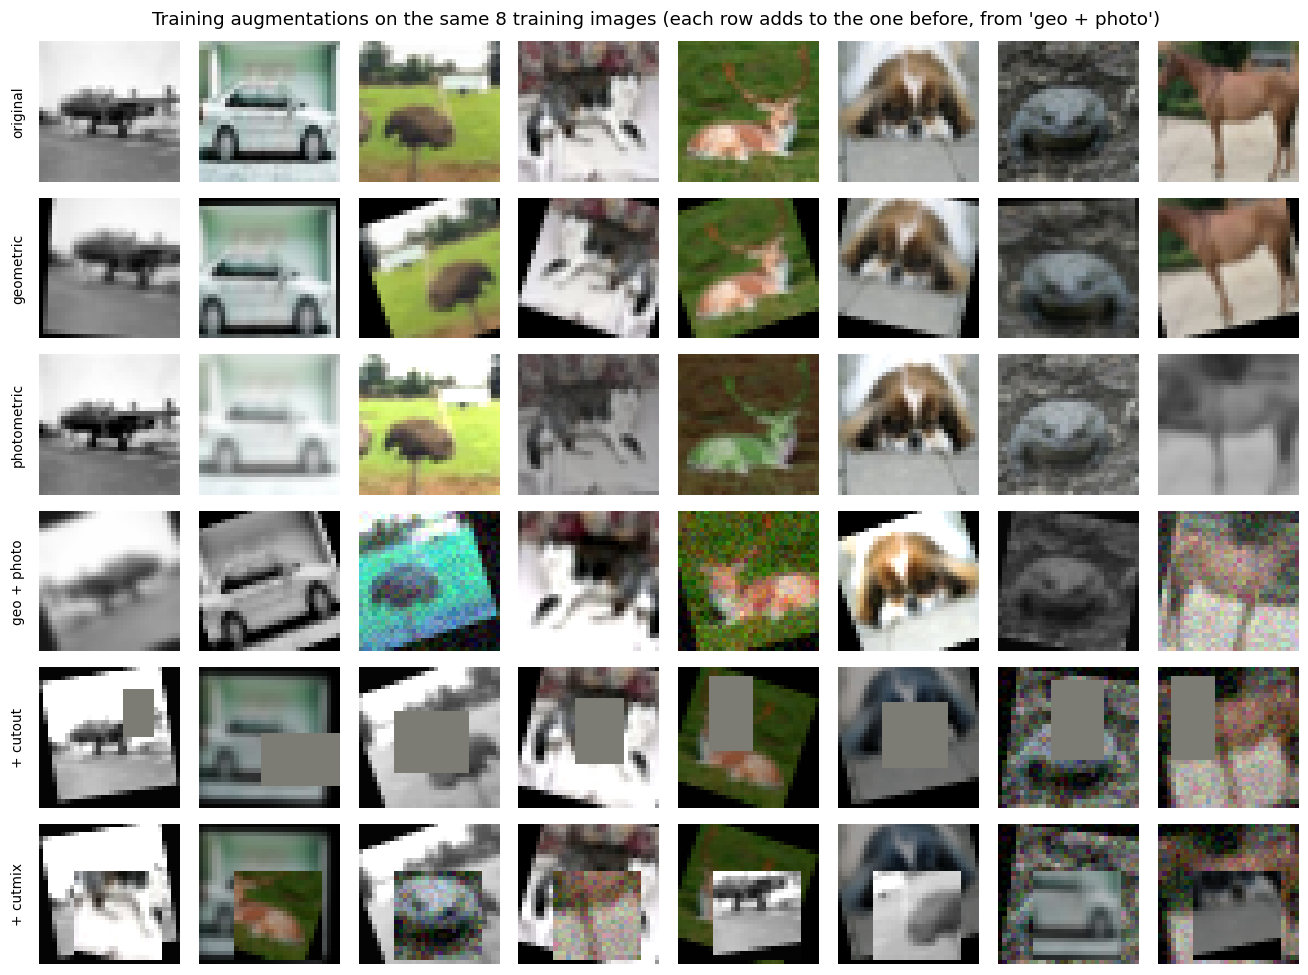

In [6]:
def aug_geometric(x, rot=20.0, scale=(0.85, 1.15), shift=4, hflip=True, vflip=False):
    n, d = x.size(0), x.device
    u = lambda: torch.rand(n, device=d) * 2 - 1
    ang = u() * rot * math.pi / 180
    sc = scale[0] + (u() + 1) / 2 * (scale[1] - scale[0])
    tx, ty = u() * shift / 16, u() * shift / 16                    # pixels -> normalized units
    flip = torch.where(torch.rand(n, device=d) < 0.5, -1.0, 1.0) if hflip else torch.ones(n, device=d)
    out = affine_batch(x, ang, sc, tx, ty, flip)
    if vflip:
        out = torch.where((torch.rand(n, device=d) < 0.5).view(-1, 1, 1, 1), out.flip(2), out)
    return out

def aug_photometric(x, bright=0.4, contrast=0.4, sat=0.4, p_gray=0.2, p_shuffle=0.2, p_blur=0.2, p_noise=0.2, noise_std=0.06):
    n, d = x.size(0), x.device
    j = lambda a: 1 + (torch.rand(n, 1, 1, 1, device=d) * 2 - 1) * a
    sel = lambda p: torch.rand(n, 1, 1, 1, device=d) < p
    gray_of = lambda t: 0.299 * t[:, 0:1] + 0.587 * t[:, 1:2] + 0.114 * t[:, 2:3]
    x = x * j(bright)
    m = x.mean((1, 2, 3), keepdim=True); x = ((x - m) * j(contrast) + m).clamp(0, 1)
    g = gray_of(x); x = ((x - g) * j(sat) + g).clamp(0, 1)
    x = torch.where(sel(p_gray), gray_of(x).expand(-1, 3, -1, -1), x)
    perm = torch.rand(n, 3, device=d).argsort(1)
    xs = torch.gather(x, 1, perm.view(n, 3, 1, 1).expand(-1, -1, x.size(2), x.size(3)))
    x = torch.where(sel(p_shuffle), xs, x)
    x = torch.where(sel(p_blur), blur_batch(x, sigma=0.8), x)
    x = torch.where(sel(p_noise), (x + torch.randn_like(x) * noise_std).clamp(0, 1), x)
    return x

def aug_cutout(x, p=0.5, lo=0.05, hi=0.25):
    n, _, H, W = x.shape; d = x.device
    area = lo + (hi - lo) * torch.rand(n, device=d); asp = 0.5 + 1.5 * torch.rand(n, device=d)
    h = torch.sqrt(area * H * W * asp).round().clamp(2, H).long(); w = (area * H * W / h.float()).round().clamp(2, W).long()
    top = (torch.rand(n, device=d) * (H - h + 1).float()).floor().long(); left = (torch.rand(n, device=d) * (W - w + 1).float()).floor().long()
    m = rect_mask(n, H, W, top, left, h, w, d) & (torch.rand(n, 1, 1, 1, device=d) < p)
    return x.masked_fill(m, 0.0)               # 0 = mean colour after normalization

def cutmix(x, y_soft, alpha=1.0, p=0.5):
    if np.random.rand() > p: return x, y_soft
    n, _, H, W = x.shape; lam = np.random.beta(alpha, alpha)
    perm = torch.randperm(n, device=x.device)
    rh, rw = int(round(H * math.sqrt(1 - lam))), int(round(W * math.sqrt(1 - lam)))
    cy, cx = np.random.randint(H), np.random.randint(W)
    y1, y2, x1, x2 = max(cy - rh // 2, 0), min(cy + rh // 2, H), max(cx - rw // 2, 0), min(cx + rw // 2, W)
    x = x.clone(); x[:, :, y1:y2, x1:x2] = x[perm][:, :, y1:y2, x1:x2]
    lam_adj = 1 - ((y2 - y1) * (x2 - x1)) / (H * W)
    return x, lam_adj * y_soft + (1 - lam_adj) * y_soft[perm]

# ---- data on the compute device, normalized once ----
dv = lambda t: t.to(device)
MEAN_d, STD_d = dv(MEAN), dv(STD)
norm = lambda t: ((t - MEAN) / STD)
Xtr_d, Ytr_d = dv(Xtr), dv(Ytr)
Xtr_n, Xva_n, Xcl_n, Xsh_n, Xhid_n = [dv(norm(t)) for t in (Xtr, Xva, Xclean, Xshift, Xhidden_only)]
Xcl_raw, Xsh_raw = dv(Xclean), dv(Xshift)

# ---- visual check of the augmentations (one fixed batch) ----
set_seed(0)
xb = Xtr_d[[0, 41, 82, 123, 164, 205, 246, 287]]
ysoft = F.one_hot(Ytr_d[[0, 41, 82, 123, 164, 205, 246, 287]], NUM_CLASSES).float()
rows = [("original", xb), ("geometric", aug_geometric(xb)), ("photometric", aug_photometric(xb)),
        ("geo + photo", aug_photometric(aug_geometric(xb)))]
xn = (aug_photometric(aug_geometric(xb)) - MEAN_d) / STD_d
rows.append(("+ cutout", aug_cutout(xn, p=1.0) * STD_d + MEAN_d))
xm, _ = cutmix(xn, ysoft, p=1.0); rows.append(("+ cutmix", xm * STD_d + MEAN_d))
fig, ax = plt.subplots(len(rows), 8, figsize=(12, 9))
for r, (name, t) in enumerate(rows):
    for c in range(8):
        ax[r, c].imshow(t[c].clamp(0, 1).permute(1, 2, 0).cpu()); ax[r, c].axis("off")
    ax[r, 0].text(-0.1, 0.5, name, transform=ax[r, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
fig.suptitle("Training augmentations on the same 8 training images (each row adds to the one before, from 'geo + photo')")
plt.tight_layout(); plt.show()

In [7]:
import pickle, pandas as pd
USE_CACHE = True   # reuse finished runs stored in results/ (set False to retrain everything from scratch)

def make_cfg(**k):
    base = dict(geo=False, photo=False, cutout=False, cutmix=False, ls=0.0, vflip=False, rot=20.0, color_inv=True)
    base.update(k); return base

HP_DEFAULT = dict(lr=0.05, wd=5e-4, drop=0.3, patience=25)

def evaluate(model, X, Y, bs=1000):
    model.eval(); preds, loss = [], 0.0
    with torch.no_grad():
        for i in range(0, len(X), bs):
            lg = model(X[i:i + bs]); loss += F.cross_entropy(lg, Y[i:i + bs].to(X.device), reduction="sum").item(); preds.append(lg.argmax(1).cpu())
    preds = torch.cat(preds); return (preds == Y.cpu()).float().mean().item(), loss / len(X), preds.numpy()

def train_one(cfg, seed, hp, epochs=EPOCHS, eval_test=True):
    set_seed(seed); t0 = time.time()
    model = Net(hp["drop"]).to(device)
    opt = torch.optim.SGD(model.parameters(), lr=hp["lr"], momentum=0.9, nesterov=True, weight_decay=hp["wd"])
    spe = math.ceil(len(Xtr_d) / BATCH_SIZE)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=hp["lr"], epochs=epochs, steps_per_epoch=spe, pct_start=0.2)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr"]}
    best_acc, best_loss, best_ep, bad, best_state = -1, 1e9, 0, 0, None
    for ep in range(epochs):
        model.train(); order = torch.randperm(len(Xtr_d)).to(device)
        for i in range(0, len(order), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]; xb, yb = Xtr_d[idx], Ytr_d[idx]
            ysoft = F.one_hot(yb, NUM_CLASSES).float() * (1 - cfg["ls"]) + cfg["ls"] / NUM_CLASSES
            if cfg["geo"]:   xb = aug_geometric(xb, rot=cfg["rot"], vflip=cfg["vflip"])
            if cfg["photo"]: xb = aug_photometric(xb, **({} if cfg["color_inv"] else dict(p_gray=0.0, p_shuffle=0.0)))
            xb = (xb - MEAN_d) / STD_d
            if cfg["cutout"]: xb = aug_cutout(xb)
            if cfg["cutmix"]: xb, ysoft = cutmix(xb, ysoft)
            loss = -(ysoft * F.log_softmax(model(xb), 1)).sum(1).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
        tra, trl, _ = evaluate(model, Xtr_n, Ytr_d); vaa, val, _ = evaluate(model, Xva_n, Yva)
        for k, v in zip(hist, [trl, tra, val, vaa, opt.param_groups[0]["lr"]]): hist[k].append(v)
        if vaa > best_acc or (vaa == best_acc and val < best_loss - 1e-4):          # early stopping on validation only
            best_acc, best_loss, best_ep, bad = vaa, val, ep, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= hp["patience"]: break
    model.load_state_dict(best_state)
    tra, _, _ = evaluate(model, Xtr_n, Ytr_d); vaa, val, _ = evaluate(model, Xva_n, Yva)
    if eval_test:   # test sets: touched only after training has finished (never inside hyper-parameter selection)
        cla, _, _ = evaluate(model, Xcl_n, Yclean); sha, _, sh_pred = evaluate(model, Xsh_n, Yshift)
    else:
        cla, sha, sh_pred = float("nan"), float("nan"), None
    return dict(hist=hist, best_ep=best_ep, epochs_run=len(hist["val_acc"]), train_acc=tra, val_acc=vaa, val_loss=val,
                clean_acc=cla, shift_acc=sha, shift_pred=sh_pred, state=best_state, hp=hp, cfg=cfg, seed=seed, secs=time.time() - t0)

def run_cached(tag, cfg, seed, hp=HP_DEFAULT, eval_test=True):
    path = os.path.join(OUT_DIR, f"run_{tag}_s{seed}.pkl")
    cached = USE_CACHE and os.path.exists(path)
    r = pickle.load(open(path, "rb")) if cached else train_one(cfg, seed, hp, eval_test=eval_test)
    if not cached: pickle.dump(r, open(path, "wb"))
    head = f"  [{tag} | seed {seed}] best epoch {r['best_ep']+1:2d}/{r['epochs_run']} | train {r['train_acc']:.3f} val {r['val_acc']:.3f} "
    tail = (f"clean {r['clean_acc']:.3f} shifted {r['shift_acc']:.3f}" if eval_test else "(test sets not evaluated)") + (f" | {r['secs']:.0f}s" + (" (loaded from results/)" if cached else ""))
    print(head + tail)
    return r

def run_all(tag, cfg, hp=HP_DEFAULT, seeds=SEEDS): return [run_cached(tag, cfg, s, hp) for s in seeds]
ms = lambda v: f"{100*np.mean(v):.1f} ± {100*np.std(v):.1f}"    # mean ± std in percent (population std over the 3 seeds)

CFG = {
  "No augmentation":                        make_cfg(),
  "Geometric only (crop, flip, rotation)":  make_cfg(geo=True),
  "Photometric only (jitter, blur, noise)": make_cfg(photo=True),
  "Geometric + photometric":                make_cfg(geo=True, photo=True),
  "+ Cutout / Random Erasing":              make_cfg(geo=True, photo=True, cutout=True),
  "+ CutMix + label smoothing":             make_cfg(geo=True, photo=True, cutout=True, cutmix=True, ls=0.1),
}
TAGS = {k: f"abl{i}" for i, k in enumerate(CFG)}

## Part A: Baseline (no augmentation)
Same network and same training recipe as everywhere else (SGD with Nesterov momentum, one-cycle learning-rate schedule, weight decay 5e-4, dropout 0.3, early stopping on validation accuracy). The only thing switched off is augmentation, trained on the 400 clean images for at most 60 epochs, 3 seeds.

  [abl0 | seed 0] best epoch 38/60 | train 1.000 val 0.500 clean 0.416 shifted 0.184 | 8s
  [abl0 | seed 1] best epoch 29/54 | train 1.000 val 0.530 clean 0.420 shifted 0.173 | 6s
  [abl0 | seed 2] best epoch 29/54 | train 1.000 val 0.520 clean 0.411 shifted 0.184 | 6s
                Split Accuracy % (mean ± std, 3 seeds)
   Train (400, clean)                      100.0 ± 0.0
     Validation (100)                       51.7 ± 1.2
  Clean test (10,000)                       41.5 ± 0.4
Shifted test (10,000)                       18.0 ± 0.5


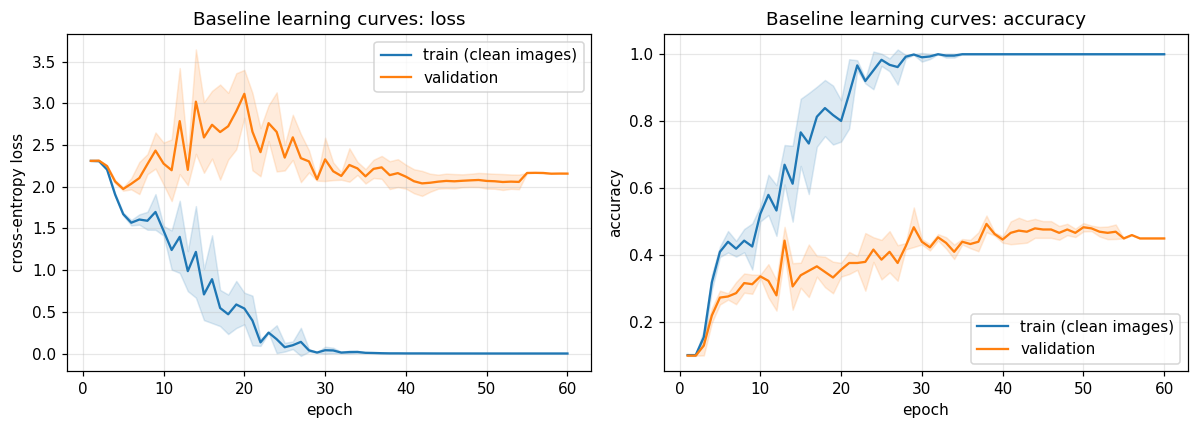

train - validation gap: 48.3 points   |   clean-test - shifted-test gap: 23.5 points   |   chance = 10.0%


In [8]:
base_runs = run_all(TAGS["No augmentation"], CFG["No augmentation"])
rows = [("Train (400, clean)", [r["train_acc"] for r in base_runs]), ("Validation (100)", [r["val_acc"] for r in base_runs]),
        ("Clean test (10,000)", [r["clean_acc"] for r in base_runs]), ("Shifted test (10,000)", [r["shift_acc"] for r in base_runs])]
dfA = pd.DataFrame([(n, ms(v)) for n, v in rows], columns=["Split", "Accuracy % (mean ± std, 3 seeds)"]); print(dfA.to_string(index=False))

def curve(ax, runs, key, label, color, ls="-"):
    L = max(len(r["hist"][key]) for r in runs)
    A = np.full((len(runs), L), np.nan)
    for i, r in enumerate(runs): A[i, :len(r["hist"][key])] = r["hist"][key]
    m, s = np.nanmean(A, 0), np.nanstd(A, 0); x = np.arange(1, L + 1)
    ax.plot(x, m, ls, color=color, label=label); ax.fill_between(x, m - s, m + s, color=color, alpha=0.15)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
curve(ax[0], base_runs, "train_loss", "train (clean images)", "tab:blue"); curve(ax[0], base_runs, "val_loss", "validation", "tab:orange")
ax[0].set(xlabel="epoch", ylabel="cross-entropy loss", title="Baseline learning curves: loss"); ax[0].legend()
curve(ax[1], base_runs, "train_acc", "train (clean images)", "tab:blue"); curve(ax[1], base_runs, "val_acc", "validation", "tab:orange")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Baseline learning curves: accuracy"); ax[1].legend()
plt.tight_layout(); plt.show()

gap_cs = np.mean([r["clean_acc"] - r["shift_acc"] for r in base_runs]) * 100
gap_tv = np.mean([r["train_acc"] - r["val_acc"] for r in base_runs]) * 100
print(f"train - validation gap: {gap_tv:.1f} points   |   clean-test - shifted-test gap: {gap_cs:.1f} points   |   chance = 10.0%")

### Analysis: what the baseline tells us
The baseline reaches **100% training accuracy** but only **51.7% on validation** and 41.5% on the clean test set (chance is 10%). The curves show the usual memorisation pattern: training loss goes to almost zero by epoch 30, while validation loss reaches its lowest value around epoch 5 (about 2.0, not far from the 2.30 of random guessing) and then never improves. The network simply learns the 400 images by heart (train–validation gap of 48.3 points).

On the shifted test set accuracy falls again to **18.0%**, another 23.5 points below the clean test. This second gap is a different problem. It is not overfitting, it is **distribution shift**: the model has never seen rotated, darkened, occluded or colour-swapped images, so what it learned on clean photos does not transfer. The first gap needs regularization and more effective data, the second needs invariances, which is what augmentation is meant to supply (Parts B to D).


## Part B: Augmentation strategy
**What I chose and why, tied to the shifted test set**

| Augmentation | Why it is in the pipeline |
|---|---|
| Rotation ±20°, scale 0.85–1.15, shift ±4 px | The test has rotations up to ±25°. Scale and shift act as random crop with padding and make the small network less dependent on exact object position. |
| Horizontal flip | Objects keep their class when mirrored, and it doubles the effective data. |
| Brightness, contrast, saturation jitter | The test images are darkened or brightened and their contrast changes. |
| Random grayscale, channel shuffle | Generic colour robustness, because with 400 images the network can latch on to exact colours. |
| Blur, noise | Cheap mild versions of corruptions that are common in real data. |
| Cutout | The test images have a rectangle covering about a quarter of the picture. |
| CutMix + label smoothing | Occlusion-like regularizer that forces the network to use several parts of an object, and soft labels that avoid over-confident predictions. |

No augmentation uses the test pipeline code, and nothing is pre-generated. Vertical flip is **not** in the default pipeline.

Below are three small experiments that back up my answers to the three questions. Their test numbers are **reported for the discussion only**; no choice in this notebook depends on them.

In [9]:
GP = CFG["Geometric + photometric"]
side_cfgs = {
    "Default (rotation ±20°, no vertical flip)": (TAGS["Geometric + photometric"], GP),
    "Default + vertical flip":                   ("side_vflip", make_cfg(geo=True, photo=True, vflip=True)),
    "Rotation ±90° instead of ±20°":             ("side_rot90", make_cfg(geo=True, photo=True, rot=90.0)),
    "Too much of everything (rot ±90°, cutout, cutmix, all colour ops)": ("side_toomuch", make_cfg(geo=True, photo=True, cutout=True, cutmix=True, ls=0.1, rot=90.0, vflip=True)),
}
side_runs = {k: run_all(t, c) for k, (t, c) in side_cfgs.items()}
dfB = pd.DataFrame([(k, ms([r["val_acc"] for r in v]), ms([r["clean_acc"] for r in v]), ms([r["shift_acc"] for r in v])) for k, v in side_runs.items()],
                   columns=["Configuration (geo + photo base)", "Val acc %", "Clean test %", "Shifted test %"])
print(dfB.to_string(index=False))

  [abl3 | seed 0] best epoch 53/60 | train 0.690 val 0.570 clean 0.421 shifted 0.227 | 8s
  [abl3 | seed 1] best epoch 47/60 | train 0.678 val 0.570 clean 0.433 shifted 0.206 | 8s
  [abl3 | seed 2] best epoch 59/60 | train 0.715 val 0.570 clean 0.440 shifted 0.223 | 8s
  [side_vflip | seed 0] best epoch 59/60 | train 0.570 val 0.510 clean 0.393 shifted 0.204 | 9s
  [side_vflip | seed 1] best epoch 60/60 | train 0.613 val 0.510 clean 0.405 shifted 0.198 | 8s
  [side_vflip | seed 2] best epoch 49/60 | train 0.560 val 0.480 clean 0.382 shifted 0.202 | 8s
  [side_rot90 | seed 0] best epoch 33/58 | train 0.433 val 0.430 clean 0.329 shifted 0.168 | 8s
  [side_rot90 | seed 1] best epoch 39/60 | train 0.463 val 0.400 clean 0.336 shifted 0.181 | 8s
  [side_rot90 | seed 2] best epoch 45/60 | train 0.505 val 0.420 clean 0.358 shifted 0.184 | 8s
  [side_toomuch | seed 0] best epoch 43/60 | train 0.347 val 0.380 clean 0.289 shifted 0.152 | 9s
  [side_toomuch | seed 1] best epoch 38/60 | train 0.403

### Answers to the three questions (numbers from the table above, 3 seeds, geometric + photometric base)
**1. Would vertical flip help or hurt?** It **hurts**. Adding it dropped validation accuracy from 57.0% to 50.0%, clean test from 43.1% to 39.3% and shifted test from 21.9% to 20.1%. CIFAR-10 photos have a fixed orientation (sky on top, ground at the bottom, cars on their wheels), so an upside-down image is something the test set never contains. Flipping vertically is label-preserving but not realistic: the network spends its limited capacity on a pose it will never see, and upside-down versions of some classes (for example ships or horses) may confuse the classifier more than they teach it. Horizontal flip is fine because mirrored scenes still look natural.

**2. Rotation up to ±90° when the test only has ±25°.** Large rotations do teach more rotation invariance, but most of the training samples then fall far outside the test range. In my runs ±90° gave 41.7% validation, 34.1% clean and 17.8% shifted accuracy, compared with 57.0%, 43.1% and 21.9% for ±20°. It lowered even the clean test accuracy by 9 points, so the network lost accuracy on upright images, which are the ones it will see most. There is a trade-off between invariance and spending capacity on irrelevant poses. A good rotation range is about the size of the expected shift (I used ±20°, close to the ±25° in the test). Larger rotations also add more black corner area, which is another artefact the test does not have.

**3. Why can too much augmentation hurt a small model?** Augmentation makes the training task harder. A network with about 64k parameters, 400 images and at most 60 epochs only has a limited ability to fit that harder task. When I stacked everything at once (rotation ±90°, vertical flip, Cutout, CutMix, all colour operations) the training accuracy fell to about 38%, the validation accuracy to 38.3% and shifted accuracy to 16.1%, which is **worse than using no augmentation at all** (18.0%). The model underfits: the transformed images destroy too much of the signal that it needs to learn the classes. Augmentation strength should be matched to model capacity, training length and the real shift, not simply maximised.


## Part C: Regularization and training design
| Technique | Setting | Where it sits and why |
|---|---|---|
| **BatchNorm** | after every convolution, before ReLU | Stabilises the activations, allows a larger learning rate, and acts as a mild regularizer through batch noise. |
| **Dropout** | only on the 160-d pooled feature vector, right before the final linear layer | Early convolutional feature maps are spatially correlated, so dropping single activations barely removes information (neighbours carry it) while it slows learning. The classifier head is the layer that can co-adapt and memorise 400 images, so that is where Dropout belongs. With BatchNorm in the conv layers, dropout between them also causes a variance shift. |
| **Weight decay** | L2 on all weights, tuned on validation | Keeps weights small so the 64k-parameter network cannot fit noise as easily. |
| **LR schedule** | one-cycle (warm-up, then cosine decay) | A high learning rate in the middle acts as regularization, and the decay at the end lets the model settle in a flat minimum. |
| **Label smoothing** | 0.1, used together with CutMix | Soft targets avoid over-confident outputs, which matter more on shifted data. |
| **Early stopping** | stop after 25 epochs without improvement in validation accuracy, restore the best epoch | Protects against fitting the training set too long. Uses validation data only. |
| **Global average pooling** | instead of FC layers | Removes the largest block of parameters in classic CNNs. |

**Hyper-parameter selection (validation only).** I use the full augmentation pipeline with seed 0 and look at the validation accuracy (ties broken by validation loss). First a 3×2 grid over learning rate and weight decay, then the dropout rate with the best pair. The runs here do not even evaluate the test sets.

  [hp_lr0.02_wd0.0005_d0.3 | seed 0] best epoch 53/60 | train 0.558 val 0.490 (test sets not evaluated) | 9s
  [hp_lr0.02_wd0.003_d0.3 | seed 0] best epoch 57/60 | train 0.527 val 0.510 (test sets not evaluated) | 9s
  [hp_lr0.05_wd0.0005_d0.3 | seed 0] best epoch 57/60 | train 0.592 val 0.530 (test sets not evaluated) | 8s
  [hp_lr0.05_wd0.003_d0.3 | seed 0] best epoch 54/60 | train 0.600 val 0.540 (test sets not evaluated) | 9s
  [hp_lr0.1_wd0.0005_d0.3 | seed 0] best epoch 51/60 | train 0.635 val 0.540 (test sets not evaluated) | 9s
  [hp_lr0.1_wd0.003_d0.3 | seed 0] best epoch 59/60 | train 0.613 val 0.550 (test sets not evaluated) | 8s
  [hp_lr0.1_wd0.003_d0.1 | seed 0] best epoch 48/60 | train 0.577 val 0.570 (test sets not evaluated) | 9s
  [hp_lr0.1_wd0.003_d0.5 | seed 0] best epoch 52/60 | train 0.505 val 0.520 (test sets not evaluated) | 9s
  lr     wd  drop  val_acc  val_loss
0.10 0.0030   0.1     0.57  1.521970
0.10 0.0030   0.3     0.55  1.466603
0.05 0.0030   0.3     0.54

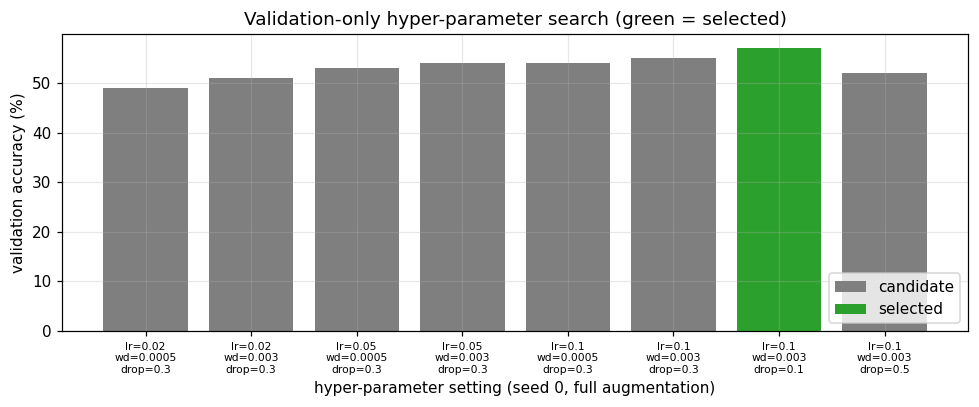

In [10]:
FULL = CFG["+ CutMix + label smoothing"]
def hp_run(hp):
    tag = f"hp_lr{hp['lr']}_wd{hp['wd']}_d{hp['drop']}"
    r = run_cached(tag, FULL, 0, hp, eval_test=False); return dict(lr=hp["lr"], wd=hp["wd"], drop=hp["drop"], val_acc=r["val_acc"], val_loss=r["val_loss"], hp=hp)

stage1 = [hp_run(dict(lr=lr, wd=wd, drop=0.3, patience=25)) for lr in (0.02, 0.05, 0.1) for wd in (5e-4, 3e-3)]
b1 = max(stage1, key=lambda t: (t["val_acc"], -t["val_loss"]))
stage2 = [hp_run(dict(lr=b1["lr"], wd=b1["wd"], drop=d, patience=25)) for d in (0.1, 0.5) if d != b1["drop"]]
allhp = stage1 + stage2
best = max(allhp, key=lambda t: (t["val_acc"], -t["val_loss"]))
best_hp = best["hp"]
dfC = pd.DataFrame([{k: t[k] for k in ("lr", "wd", "drop", "val_acc", "val_loss")} for t in allhp]).sort_values(["val_acc", "val_loss"], ascending=[False, True])
print(dfC.to_string(index=False)); print("\nselected hyper-parameters (validation only):", best_hp)

fig, ax = plt.subplots(figsize=(9, 3.8))
labels = [f"lr={t['lr']}\nwd={t['wd']}\ndrop={t['drop']}" for t in allhp]
bars = ax.bar(range(len(allhp)), [100 * t["val_acc"] for t in allhp], color=["tab:green" if t is best else "tab:gray" for t in allhp])
ax.set_xticks(range(len(allhp))); ax.set_xticklabels(labels, fontsize=7); ax.set_ylabel("validation accuracy (%)"); ax.set_xlabel("hyper-parameter setting (seed 0, full augmentation)")
ax.set_title("Validation-only hyper-parameter search (green = selected)"); ax.legend([bars[0], bars[allhp.index(best)]], ["candidate", "selected"], loc="lower right")
plt.tight_layout(); plt.show()

## Part D: Ablation study
Rows 1–6 add one family of augmentation at a time and share the default hyper-parameters (lr 0.05, weight decay 5e-4, dropout 0.3). The last row is the **final model**: the full pipeline with the hyper-parameters chosen in Part C. All numbers are mean ± std (percent) over seeds 0, 1, 2.

  [abl0 | seed 0] best epoch 38/60 | train 1.000 val 0.500 clean 0.416 shifted 0.184 | 8s (loaded from results/)
  [abl0 | seed 1] best epoch 29/54 | train 1.000 val 0.530 clean 0.420 shifted 0.173 | 6s (loaded from results/)
  [abl0 | seed 2] best epoch 29/54 | train 1.000 val 0.520 clean 0.411 shifted 0.184 | 6s (loaded from results/)
  [abl1 | seed 0] best epoch 45/60 | train 0.920 val 0.520 clean 0.407 shifted 0.170 | 7s
  [abl1 | seed 1] best epoch 51/60 | train 0.962 val 0.490 clean 0.416 shifted 0.177 | 7s
  [abl1 | seed 2] best epoch 46/60 | train 0.905 val 0.510 clean 0.412 shifted 0.190 | 7s
  [abl2 | seed 0] best epoch 42/60 | train 1.000 val 0.490 clean 0.352 shifted 0.177 | 8s
  [abl2 | seed 1] best epoch 55/60 | train 1.000 val 0.530 clean 0.370 shifted 0.195 | 7s
  [abl2 | seed 2] best epoch 58/60 | train 1.000 val 0.490 clean 0.356 shifted 0.181 | 8s
  [abl3 | seed 0] best epoch 53/60 | train 0.690 val 0.570 clean 0.421 shifted 0.227 | 8s (loaded from results/)
  [abl3 

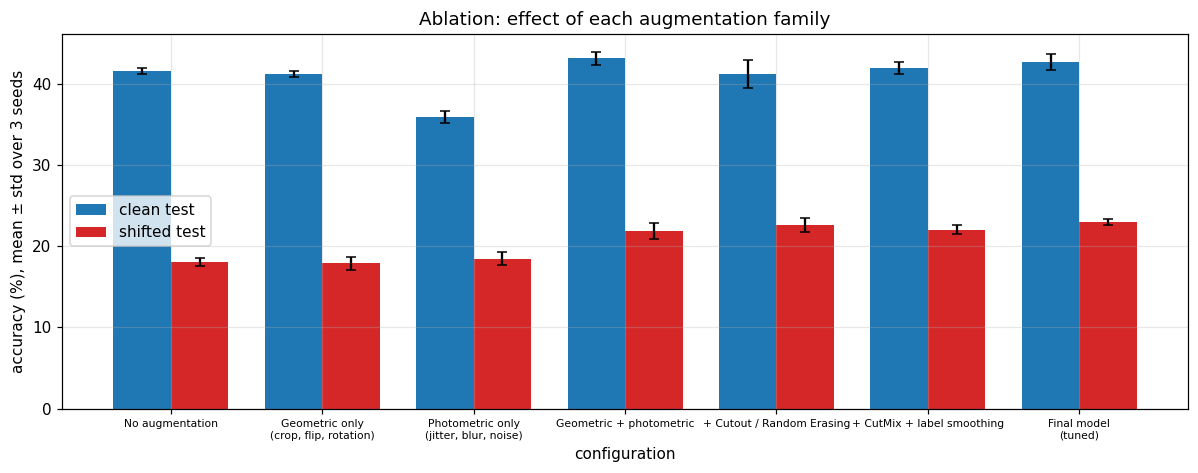


Shifted-test accuracy (%) per corruption subset (mean of 3 seeds):
                         Configuration strong rotation (|angle| > 15°) mild rotation (|angle| ≤ 15°) dark or bright (factor <0.75 or >1.25) low contrast (factor < 0.8) channel-swapped colours intact blurred noisy
                       No augmentation                            16.8                          18.8                                   17.4                        15.4            16.0           20.1    15.9  18.4
 Geometric only (crop, flip, rotation)                            17.0                          18.4                                   16.9                        16.5            15.2           20.6    16.3  17.8
Photometric only (jitter, blur, noise)                            16.3                          19.8                                   18.1                        17.3            17.9           19.0    17.9  17.7
               Geometric + photometric                            20.9          

In [11]:
final_same = (best_hp == HP_DEFAULT)
abl = {name: run_all(TAGS[name], cfg) for name, cfg in CFG.items()}
abl["Final model (tuned)"] = abl["+ CutMix + label smoothing"] if final_same else run_all("final", FULL, best_hp)

dfD = pd.DataFrame([(n, ms([r["val_acc"] for r in v]), ms([r["clean_acc"] for r in v]), ms([r["shift_acc"] for r in v])) for n, v in abl.items()],
                   columns=["Configuration", "Val Acc %", "Clean Test %", "Shifted Test %"])
print(dfD.to_string(index=False)); dfD.to_csv(os.path.join(OUT_DIR, "ablation_table.csv"), index=False)

names = list(abl); x = np.arange(len(names)); w = 0.38
cm = [100 * np.mean([r["clean_acc"] for r in abl[n]]) for n in names]; cs = [100 * np.std([r["clean_acc"] for r in abl[n]]) for n in names]
sm = [100 * np.mean([r["shift_acc"] for r in abl[n]]) for n in names]; ss = [100 * np.std([r["shift_acc"] for r in abl[n]]) for n in names]
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.bar(x - w/2, cm, w, yerr=cs, capsize=3, label="clean test", color="tab:blue"); ax.bar(x + w/2, sm, w, yerr=ss, capsize=3, label="shifted test", color="tab:red")
ax.set_xticks(x); ax.set_xticklabels([n.replace(" (", "\n(").replace("+ ", "+ ") for n in names], fontsize=7, rotation=0)
ax.set_ylabel("accuracy (%), mean ± std over 3 seeds"); ax.set_xlabel("configuration"); ax.set_title("Ablation: effect of each augmentation family"); ax.legend()
plt.tight_layout(); plt.show()

# ---- which corruption does each augmentation family help against? accuracy of the shifted test split by corruption ----
mt = shift_meta
subsets = {"strong rotation (|angle| > 15°)": np.abs(mt["angle"]) > 15, "mild rotation (|angle| ≤ 15°)": np.abs(mt["angle"]) <= 15,
           "dark or bright (factor <0.75 or >1.25)": (mt["bright"] < 0.75) | (mt["bright"] > 1.25), "low contrast (factor < 0.8)": mt["contrast"] < 0.8,
           "channel-swapped": mt["swapped"], "colours intact": ~mt["swapped"], "blurred": mt["blur"], "noisy": mt["noise"]}
Ys = Yshift.numpy(); rows = []
for n in names:
    row = {"Configuration": n}
    for sname, mask in subsets.items():
        row[sname] = f"{100*np.mean([(r['shift_pred'][mask] == Ys[mask]).mean() for r in abl[n]]):.1f}"
    rows.append(row)
dfSub = pd.DataFrame(rows); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
print("\nShifted-test accuracy (%) per corruption subset (mean of 3 seeds):"); print(dfSub.to_string(index=False)); dfSub.to_csv(os.path.join(OUT_DIR, "subset_accuracy.csv"), index=False)

step = [(names[i], 100*np.mean([r["shift_acc"] for r in abl[names[i]]]) - 100*np.mean([r["shift_acc"] for r in abl[names[i-1]]])) for i in range(1, 6)]
base_sh = sm[0]
print("\nShifted-test gain over 'No augmentation':", {n: round(sm[i] - base_sh, 1) for i, n in enumerate(names) if i > 0})
print("Step-by-step change of the stacked pipeline (geo+photo -> +cutout -> +cutmix):", [(n, round(d, 1)) for n, d in step[3:]])

### Analysis: which augmentation helped and why
**Largest gain.** Combining geometric and photometric augmentation gave the biggest single jump: shifted accuracy went from 18.0% to 21.9% (+3.8 points), and validation from 51.7% to 57.0%. Neither family helped alone (geometric 17.9%, photometric 18.4%). The training accuracy shows why: with no augmentation, geometric only or photometric only the model still memorises the training set (about 91–100%), but with both it drops to about 69%. Only the combination was strong enough to stop memorisation.

**Why it matches the shifted test.** The shifted images mix several corruptions at once (rotation, brightness/contrast change, noise, blur, colour swap), so the model needs invariance to several of them together. The breakdown by corruption (table above) shows that geometric + photometric improved every subset: strong rotation (16.8 → 20.9), dark or bright (17.4 → 21.3), low contrast (15.4 → 20.7), channel-swapped (16.0 → 19.5) and noisy images (18.4 → 22.1). Photometric alone did help a little on the colour-related subsets (low contrast +1.9, channel-swapped +1.9) but it cost clean accuracy (41.5 → 35.9).

**Cutout** was the best add-on (+0.7 points, 22.6%). The shifted test has about 25% of every image covered, which is what Cutout trains for, and it improved every subset slightly. The gain is within one standard deviation (0.9), so I treat it as a small positive effect, not a proven one. **CutMix + label smoothing** did not help (22.0%, validation dropped from 57.3% to 54.0%). With only 400 images and 60 epochs, mixing labels probably makes the training problem too hard. The **tuned final model** (lr 0.1, weight decay 3e-3, dropout 0.1, chosen on validation only) is the best at 23.0 ± 0.4%.

**Reality check.** The full pipeline adds 4.9 points, which closes only about a fifth of the 23.5-point gap between clean and shifted accuracy. With 400 images and 64k parameters, shifted accuracy stays low. Also, the validation set has only 100 images, so one image is one point, and the small differences between hyper-parameter settings (1 to 3 images) should not be over-interpreted.


## Part E: Error analysis (final model, 3 seeds)

     class accuracy % (mean ± std)
  airplane              26.9 ± 1.6
automobile              23.8 ± 0.7
      bird              17.6 ± 5.1
       cat               9.2 ± 1.1
      deer              36.2 ± 3.5
       dog              12.4 ± 2.1
      frog              26.0 ± 4.2
     horse              14.7 ± 3.4
      ship              30.8 ± 1.0
     truck              31.9 ± 3.3


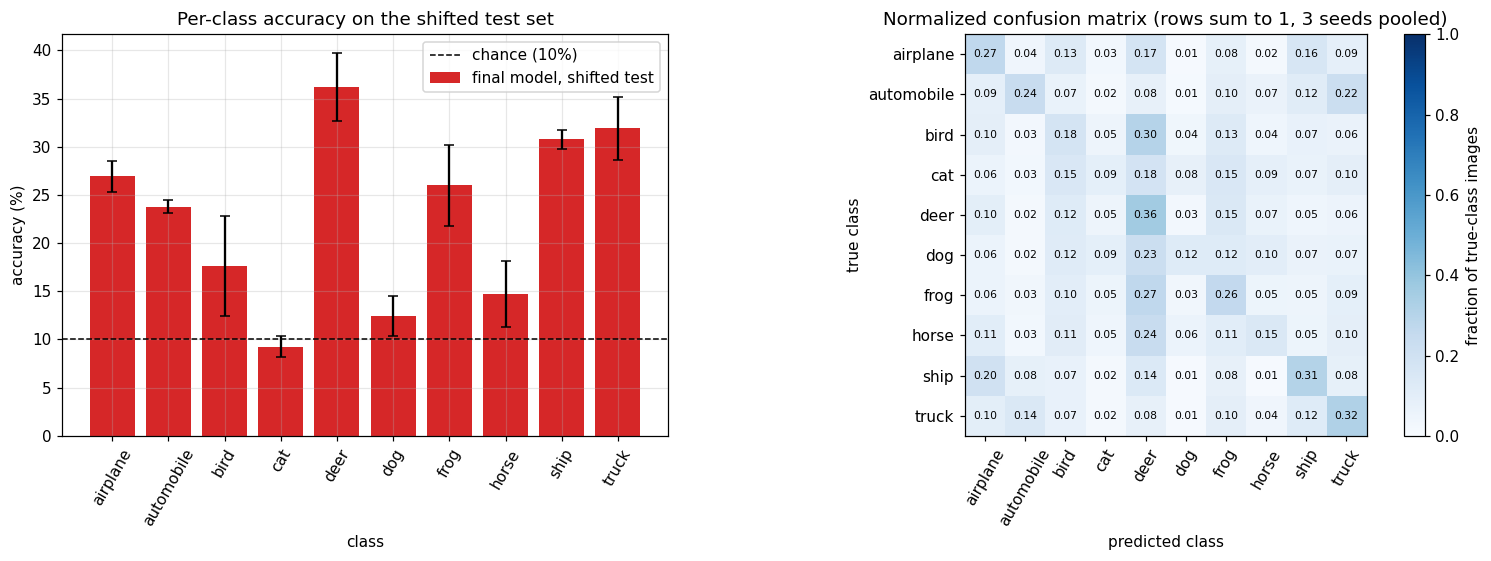

Most confused (true -> predicted, fraction of the true class):
         bird -> deer       0.30
         frog -> deer       0.27
        horse -> deer       0.24
          dog -> deer       0.23
   automobile -> truck      0.22
         ship -> airplane   0.20
          cat -> deer       0.18
     airplane -> deer       0.17


In [12]:
final_runs = abl["Final model (tuned)"]
def load_model(r):
    m = Net(r["hp"]["drop"]).to(device); m.load_state_dict(r["state"]); return m.eval()
final_models = [load_model(r) for r in final_runs]

# ---- 1. per-class accuracy and normalized confusion matrix (predictions pooled over the 3 seeds) ----
pc = np.array([[(r["shift_pred"][Ys == c] == c).mean() for c in range(NUM_CLASSES)] for r in final_runs]) * 100
dfPC = pd.DataFrame({"class": CLASSES, "accuracy % (mean ± std)": [f"{pc[:, c].mean():.1f} ± {pc[:, c].std():.1f}" for c in range(NUM_CLASSES)]}); print(dfPC.to_string(index=False))
conf = np.zeros((NUM_CLASSES, NUM_CLASSES))
for r in final_runs:
    for t, p in zip(Ys, r["shift_pred"]): conf[t, p] += 1
conf_n = conf / conf.sum(1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax[0].bar(CLASSES, pc.mean(0), yerr=pc.std(0), capsize=3, color="tab:red", label="final model, shifted test"); ax[0].axhline(10, color="k", ls="--", lw=1, label="chance (10%)")
ax[0].set_xlabel("class"); ax[0].set_ylabel("accuracy (%)"); ax[0].set_title("Per-class accuracy on the shifted test set"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend()
im = ax[1].imshow(conf_n, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): ax[1].text(j, i, f"{conf_n[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if conf_n[i, j] > 0.5 else "black")
ax[1].set_xticks(range(NUM_CLASSES)); ax[1].set_xticklabels(CLASSES, rotation=60); ax[1].set_yticks(range(NUM_CLASSES)); ax[1].set_yticklabels(CLASSES)
ax[1].set_xlabel("predicted class"); ax[1].set_ylabel("true class"); ax[1].set_title("Normalized confusion matrix (rows sum to 1, 3 seeds pooled)"); ax[1].grid(False)
plt.colorbar(im, ax=ax[1], label="fraction of true-class images"); plt.tight_layout(); plt.show()

off = [(conf_n[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j]
print("Most confused (true -> predicted, fraction of the true class):")
for v, a, b in sorted(off, reverse=True)[:8]: print(f"   {a:>10s} -> {b:<10s} {v:.2f}")

### Analysis: per-class accuracy and confusion
The easiest classes on the shifted test are **deer (36.2%), truck (31.9%), ship (30.8%) and airplane (26.9%)**. The hardest are **cat (9.2%, about chance), dog (12.4%) and horse (14.7%)**, followed by bird (17.6%).

The confusion matrix shows a clear pattern: many classes are pushed into **deer**: bird → deer 30%, frog → deer 27%, horse → deer 24%, dog → deer 23%, cat → deer 18%, airplane → deer 17%. Deer has the highest recall, but partly because it acts as a "dump" class for uncertain images. My explanation (a hypothesis, I did not test it) is that blur, low contrast and occlusion remove the fine detail that separates animals, and what remains is a dull natural-looking background similar to deer images. The other large confusions are between similar vehicles and backgrounds: automobile → truck (22%) and ship → airplane (20%, both often have a uniform blue sky or water background). Animal classes with similar body shapes (cat/dog/horse/deer/bird) rely on fine details and textures, which the corruptions destroy, so they are hardest; vehicles are recognised more by overall shape and context, which survives better.


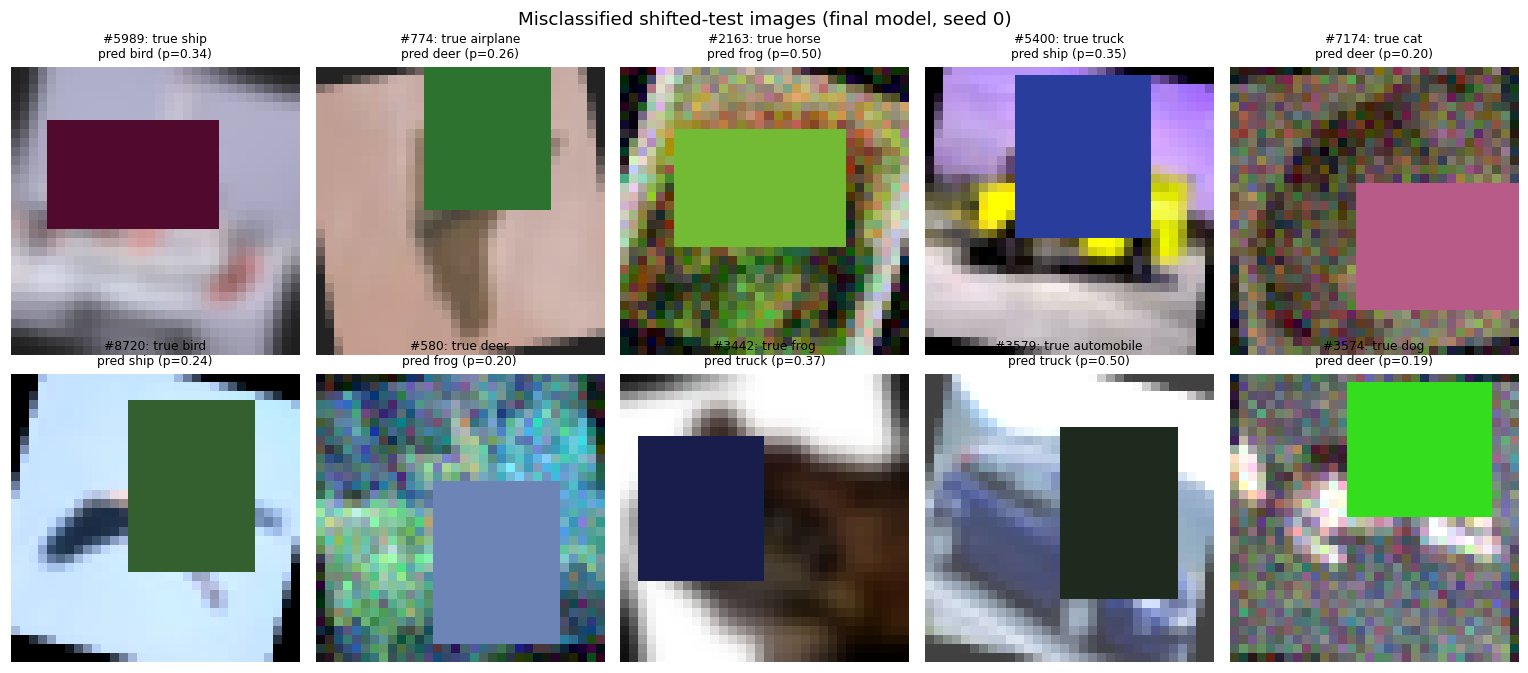

 image       true predicted confidence                                                   corruptions on this image
  5989       ship      bird       0.34                                                       blurred, 22% occluded
   774   airplane      deer       0.26                        low contrast (x0.77), channels swapped, 22% occluded
  2163      horse      frog       0.50                                           rotated -17°, noisy, 24% occluded
  5400      truck      ship       0.35                              bright (x1.27), channels swapped, 26% occluded
  7174        cat      deer       0.20                     dark (x0.72), low contrast (x0.63), noisy, 25% occluded
  8720       bird      ship       0.24                                                bright (x1.38), 26% occluded
   580       deer      frog       0.20 bright (x1.43), low contrast (x0.76), noisy, channels swapped, 25% occluded
  3442       frog     truck       0.37                                          

In [13]:
# ---- 3. at least 8 misclassified shifted-test images (seed-0 final model) with the corruptions that were applied ----
m0 = final_models[0]; pred0 = final_runs[0]["shift_pred"]
wrong = np.where(pred0 != Ys)[0]; rs = np.random.RandomState(0); rs.shuffle(wrong)
chosen, seen = [], set()
for i in wrong:
    if Ys[i] not in seen: chosen.append(int(i)); seen.add(Ys[i])
    if len(chosen) == 10: break
with torch.no_grad(): probs = F.softmax(m0(Xsh_n[chosen]), 1).cpu().numpy()
def describe(i):
    f = []
    if abs(mt["angle"][i]) > 15: f.append(f"rotated {mt['angle'][i]:+.0f}°")
    if mt["bright"][i] < 0.75: f.append(f"dark (x{mt['bright'][i]:.2f})")
    if mt["bright"][i] > 1.25: f.append(f"bright (x{mt['bright'][i]:.2f})")
    if mt["contrast"][i] < 0.8: f.append(f"low contrast (x{mt['contrast'][i]:.2f})")
    if mt["blur"][i]: f.append("blurred")
    if mt["noise"][i]: f.append("noisy")
    if mt["swapped"][i]: f.append("channels swapped")
    f.append(f"{100*mt['occ_area'][i]:.0f}% occluded"); return ", ".join(f)
fig, ax = plt.subplots(2, 5, figsize=(14, 6.2))
for k, i in enumerate(chosen):
    a = ax[k // 5, k % 5]; a.imshow(Xshift[i].permute(1, 2, 0)); a.axis("off")
    a.set_title(f"#{i}: true {CLASSES[Ys[i]]}\npred {CLASSES[pred0[i]]} (p={probs[k, pred0[i]]:.2f})", fontsize=8)
fig.suptitle("Misclassified shifted-test images (final model, seed 0)"); plt.tight_layout(); plt.show()
dfMis = pd.DataFrame([(i, CLASSES[Ys[i]], CLASSES[pred0[i]], f"{probs[k, pred0[i]]:.2f}", describe(i)) for k, i in enumerate(chosen)], columns=["image", "true", "predicted", "confidence", "corruptions on this image"])
pd.set_option("display.max_colwidth", 120); print(dfMis.to_string(index=False))

### Analysis: ten misclassified images (final model, seed 0, one image from each true class)
Every image has a quarter of its area covered by the occluder (22–26%), so occlusion is part of every failure, but the table shows additional factors that stack on top of it:
- **Photometric extremes (7 of 10)**: 774 (low contrast), 5400 and 8720 (bright), 7174 (dark + low contrast), 580 and 3579 (bright + low contrast), 3574 (bright). Washed-out or very dark images lose edges and texture. Example: the dark, low-contrast cat (7174) is predicted as deer with confidence only 0.20.
- **Channel swap (4 of 10)**: 774, 5400, 580, 3574. When colours change, class-typical colours mislead the model, e.g. the airplane (774) with swapped channels is predicted as deer and the truck (5400) as ship.
- **Noise (4 of 10)** and **blur (2 of 10: 5989 and 3442)** remove fine detail. In 5989 (ship → bird) and 3442 (frog → truck) the blur plus occlusion remove most of the shape detail.
- **Rotation** is a visible factor only in 2163 (−17°, together with noise): horse → frog, one of the two most confident mistakes (0.50).
- **Plausible class confusion**: automobile → truck (3579, confidence 0.50) is a natural mistake between similar vehicles, made worse by very bright, low-contrast colours.

Most wrong predictions have low confidence (0.19 to 0.37, with 0.10 being uniform), so the model is mostly unsure rather than confidently wrong. Three of the ten images are predicted as deer, matching the "deer sink" in the confusion matrix. Caveat: this is one seed and ten images, so it illustrates the failure modes, it is not a statistic.


  [ctrl_nocolor | seed 0] best epoch 50/60 | train 0.707 val 0.570 clean 0.425 shifted 0.190 | 8s
  [ctrl_nocolor | seed 1] best epoch 52/60 | train 0.725 val 0.480 clean 0.411 shifted 0.185 | 9s
  [ctrl_nocolor | seed 2] best epoch 53/60 | train 0.733 val 0.460 clean 0.419 shifted 0.200 | 9s
                                             Model Clean test % Hidden corruption only % …on the swapped half only % Grayscale test % Colour-inverted test % Drop clean→hidden (pts)
                        No augmentation (baseline)   41.5 ± 0.4               35.9 ± 0.1                  29.5 ± 0.5       34.8 ± 0.5             12.0 ± 0.3                     5.7
    Final model (with grayscale + channel shuffle)   42.7 ± 1.0               37.9 ± 1.2                  32.6 ± 1.5       36.6 ± 1.3             13.2 ± 1.0                     4.8
Control: same, WITHOUT grayscale + channel shuffle   41.9 ± 0.6               32.3 ± 0.4                  22.2 ± 0.4       29.3 ± 1.0              8.4 ± 0.5       

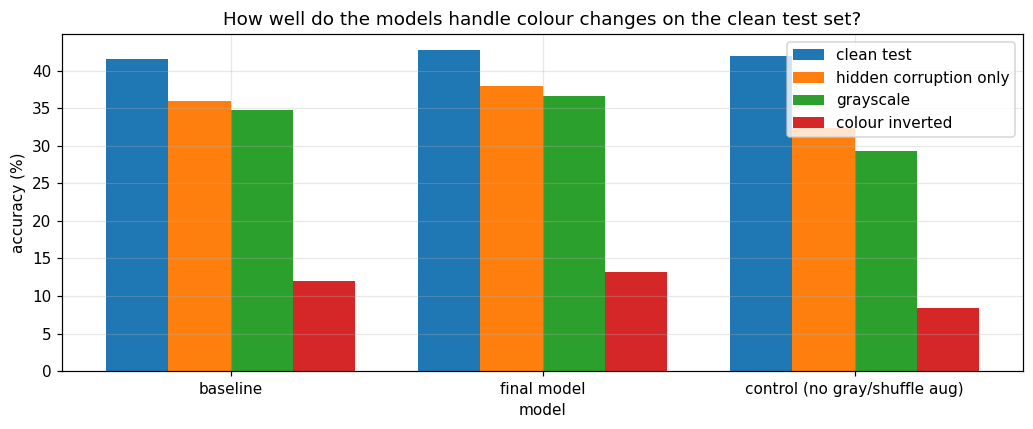

In [18]:
# ---- 4. hidden-corruption test: ONLY the hidden corruption (channel swap on 50% of images) applied to the clean test set ----
def acc_on(model, X): return evaluate(model, X, Yclean)[0]
inv_n   = dv(norm(1 - Xclean))                                                      # a colour change nobody trained on: colour inversion
gray_n  = dv(norm((0.299 * Xclean[:, 0:1] + 0.587 * Xclean[:, 1:2] + 0.114 * Xclean[:, 2:3]).expand(-1, 3, -1, -1)))
swap_mask = shift_meta["swapped"]

# control: same pipeline, but without grayscale / channel-shuffle augmentation
ctrl_cfg = dict(FULL, color_inv=False)
ctrl_runs = run_all("ctrl_nocolor", ctrl_cfg, best_hp)
groups = {"No augmentation (baseline)": base_runs, "Final model (with grayscale + channel shuffle)": final_runs, "Control: same, WITHOUT grayscale + channel shuffle": ctrl_runs}
rows = []
for n, rr in groups.items():
    ms_ = [load_model(r) for r in rr]
    c  = [acc_on(m, Xcl_n) for m in ms_]; h = [acc_on(m, Xhid_n) for m in ms_]
    hs = [evaluate(m, Xhid_n[torch.from_numpy(swap_mask).to(device)], Yclean[torch.from_numpy(swap_mask)])[0] for m in ms_]
    iv = [acc_on(m, inv_n) for m in ms_]; gr = [acc_on(m, gray_n) for m in ms_]
    rows.append((n, ms(c), ms(h), ms(hs), ms(gr), ms(iv), f"{100*(np.mean(c)-np.mean(h)):.1f}"))
dfH = pd.DataFrame(rows, columns=["Model", "Clean test %", "Hidden corruption only %", "…on the swapped half only %", "Grayscale test %", "Colour-inverted test %", "Drop clean→hidden (pts)"])
print(dfH.to_string(index=False)); dfH.to_csv(os.path.join(OUT_DIR, "hidden_corruption.csv"), index=False)

fig, ax = plt.subplots(figsize=(9.5, 4)); x = np.arange(3); w = 0.2
for k, (col, lab) in enumerate([("Clean test %", "clean test"), ("Hidden corruption only %", "hidden corruption only"), ("Grayscale test %", "grayscale"), ("Colour-inverted test %", "colour inverted")]):
    ax.bar(x + (k - 1.5) * w, [float(v.split(" ")[0]) for v in dfH[col]], w, label=lab)
ax.set_xticks(x); ax.set_xticklabels(["baseline", "final model", "control (no gray/shuffle aug)"]); ax.set_xlabel("model"); ax.set_ylabel("accuracy (%)")
ax.set_title("How well do the models handle colour changes on the clean test set?"); ax.legend(); plt.tight_layout(); plt.show()

### Analysis: hidden corruption (random channel swap on 50% of the clean test images)
| Model | Clean | Hidden corruption only | Drop |
|---|---|---|---|
| Baseline, no augmentation | 41.5% | 35.9% | 5.7 pts |
| Final model (with grayscale + channel shuffle) | 42.7% | 37.9% | 4.8 pts |
| Control: same pipeline without grayscale + channel shuffle | 41.9% | 32.3% | 9.5 pts |

**Did the augmentation generalise?** Partly, and only because I put colour augmentation in. The final model loses 4.8 points, roughly half of the 9.5 points lost by the control that was trained with the same recipe but without grayscale and channel shuffle. On the swapped half alone the final model reaches 32.6% against 22.2% for the control. So the colour-robust augmentation clearly helped for this corruption. I added grayscale and channel shuffle as generic colour-robustness augmentations before looking at any result, but I did choose them with colour shifts in mind, so this is not proof that the model handles unknown corruptions in general.

**Limits of the generalisation.** On a colour change nobody trained for, **colour inversion**, every model collapses to about chance (final 13.2%, baseline 12.0%, control 8.4%). So the robustness is specific to the colour changes seen during training (grayscale and channel permutations), it does not extend to arbitrary colour changes. One more point: the control is *less* robust than the baseline (9.5 vs 5.7 points drop). A possible reason is that colour-jitter augmentation without grayscale or shuffling makes the model rely more on colour; I did not test this.


## Part F (bonus): Test-time augmentation
Each test image is shown to the model in N views (identity, horizontal flip, ±2 px shifts in x and y, and flip + shift), and the softmax outputs are averaged. The final models of all 3 seeds are used. Inference time is measured for the whole 10,000-image shifted test set.

 views N Shifted-test acc % (mean ± std) change vs N=1 (pts) inference time (10k images) relative cost
       1                      23.0 ± 0.4                +0.0                      0.23 s          1.0x
       2                      23.1 ± 0.3                +0.2                      0.47 s          2.1x
       4                      23.0 ± 0.3                +0.0                      0.95 s          4.2x
       8                      22.9 ± 0.2                -0.1                      1.91 s          8.5x


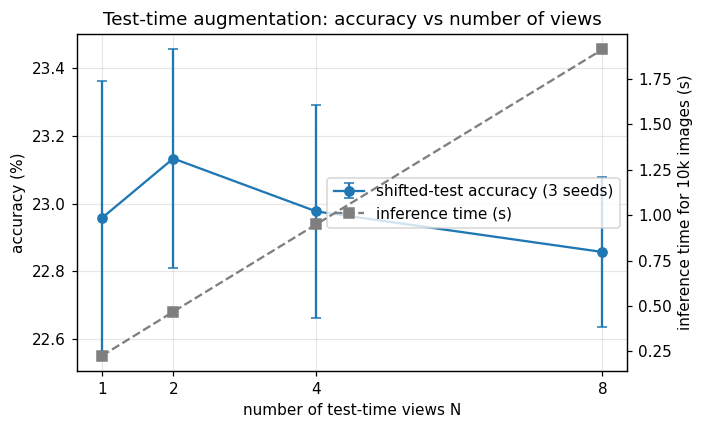

In [19]:
def view_batch(xraw, k):
    n = xraw.size(0); z = torch.zeros(n, device=xraw.device); o = torch.ones(n, device=xraw.device); s = 2 / 16
    specs = [(0, 0, 1), (0, 0, -1), (s, 0, 1), (-s, 0, 1), (0, s, 1), (0, -s, 1), (s, 0, -1), (-s, 0, -1)]
    tx, ty, fl = specs[k]
    return xraw if k == 0 else affine_batch(xraw, z, o, z + tx, z + ty, o * fl)

def tta_probs(model, Xraw, n_views, bs=1000):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(Xraw), bs):
            xb = Xraw[i:i + bs]; p = 0
            for k in range(n_views): p = p + F.softmax(model((view_batch(xb, k) - MEAN_d) / STD_d), 1)
            out.append((p / n_views).cpu())
    return torch.cat(out)

Nviews = [1, 2, 4, 8]; res = {n: [] for n in Nviews}; times = {n: [] for n in Nviews}
for m in final_models:
    for n in Nviews:
        t0 = time.time(); p = tta_probs(m, Xsh_raw, n); times[n].append(time.time() - t0)
        res[n].append((p.argmax(1) == Yshift).float().mean().item())
dfF = pd.DataFrame([(n, ms(res[n]), f"{100*(np.mean(res[n])-np.mean(res[1])):+.1f}", f"{np.mean(times[n]):.2f} s", f"{np.mean(times[n])/np.mean(times[1]):.1f}x") for n in Nviews],
                   columns=["views N", "Shifted-test acc % (mean ± std)", "change vs N=1 (pts)", "inference time (10k images)", "relative cost"])
print(dfF.to_string(index=False))
fig, ax = plt.subplots(figsize=(6.5, 4)); mm = [100*np.mean(res[n]) for n in Nviews]; sd = [100*np.std(res[n]) for n in Nviews]
ax.errorbar(Nviews, mm, yerr=sd, marker="o", capsize=3, label="shifted-test accuracy (3 seeds)"); ax.set_xticks(Nviews)
ax.set_xlabel("number of test-time views N"); ax.set_ylabel("accuracy (%)"); ax.set_title("Test-time augmentation: accuracy vs number of views")
ax2 = ax.twinx(); ax2.plot(Nviews, [np.mean(times[n]) for n in Nviews], "s--", color="tab:gray", label="inference time (s)"); ax2.set_ylabel("inference time for 10k images (s)"); ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="center right"); plt.tight_layout(); plt.show()

### Analysis: test-time augmentation
TTA did **not help**. Shifted-test accuracy with 1 view is 23.0 ± 0.4%, with 2 views 23.1 ± 0.3%, with 4 views 23.0 ± 0.3% and with 8 views 22.9 ± 0.2%. All of these differences (+0.2 to −0.1 points) are smaller than the seed-to-seed standard deviation, so there is no real change. The cost grows almost linearly with the number of views: 8 views took about 8× the inference time of one view (0.23 s to 1.9 s for 10,000 images on the Colab runtime I used).

The most likely reason is that the views I used (horizontal flip and ±2 px shifts) are things the model has already learned to ignore through training augmentation, so the averaged predictions barely differ. The corruptions that actually cause the errors (occlusion, strong colour and contrast changes, noise) are not fixed by flips and small shifts. Views that imitate those corruptions (brightness/contrast changes, grayscale, a different occluder position) might help, but I did not test them. For this model TTA is not worth the extra inference cost.


## Final numbers, summary file
The next cell collects the final results into `results/summary.json` and creates the one-page Word summary `results/Results_Summary.docx` from them. Every number in it comes from the cells above.

In [16]:
fin = abl["Final model (tuned)"]
fin_sh, fin_cl, fin_va = [r["shift_acc"] for r in fin], [r["clean_acc"] for r in fin], [r["val_acc"] for r in fin]
bs_ = [r["shift_acc"] for r in abl["No augmentation"]]
summary = dict(seeds=SEEDS, params=int(n_params), best_hp=best_hp, final_shift=ms(fin_sh), final_clean=ms(fin_cl), final_val=ms(fin_va),
               baseline_shift=ms(bs_), baseline_clean=ms([r["clean_acc"] for r in abl["No augmentation"]]),
               ablation=dfD.values.tolist(), tta8=dfF.values.tolist()[-1], hidden=dfH.values.tolist(),
               gain_over_baseline={n: round(sm[i] - sm[0], 1) for i, n in enumerate(names) if i > 0},
               stack_steps=[(n, round(d, 1)) for n, d in step])
json.dump(summary, open(os.path.join(OUT_DIR, "summary.json"), "w"), indent=1, default=str)
print(json.dumps({k: summary[k] for k in ("params", "best_hp", "final_val", "final_clean", "final_shift", "baseline_shift", "gain_over_baseline", "stack_steps")}, indent=1, default=str))

{
 "params": 64402,
 "best_hp": {
  "lr": 0.1,
  "wd": 0.003,
  "drop": 0.1,
  "patience": 25
 },
 "final_val": "56.7 \u00b1 0.5",
 "final_clean": "42.7 \u00b1 1.0",
 "final_shift": "23.0 \u00b1 0.4",
 "baseline_shift": "18.0 \u00b1 0.5",
 "gain_over_baseline": {
  "Geometric only (crop, flip, rotation)": -0.1,
  "Photometric only (jitter, blur, noise)": 0.4,
  "Geometric + photometric": 3.8,
  "+ Cutout / Random Erasing": 4.6,
  "+ CutMix + label smoothing": 4.0,
  "Final model (tuned)": 4.9
 },
 "stack_steps": [
  [
   "Geometric only (crop, flip, rotation)",
   -0.1
  ],
  [
   "Photometric only (jitter, blur, noise)",
   0.6
  ],
  [
   "Geometric + photometric",
   3.4
  ],
  [
   "+ Cutout / Random Erasing",
   0.7
  ],
  [
   "+ CutMix + label smoothing",
   -0.6
  ]
 ]
}


In [20]:
# ---- one-page Word summary (python-docx) built from the numbers above ----
try:
    from docx import Document
except ImportError:
    import subprocess, sys; subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "python-docx"]); from docx import Document
from docx.shared import Pt, Cm
doc = Document()
for s_ in doc.sections: s_.top_margin = s_.bottom_margin = Cm(1.6); s_.left_margin = s_.right_margin = Cm(1.9)
st = doc.styles["Normal"]; st.font.name = "Calibri"; st.font.size = Pt(10)
def P(text="", bold=False, size=None, after=3):
    p = doc.add_paragraph(); r = p.add_run(text); r.bold = bold
    if size: r.font.size = Pt(size)
    p.paragraph_format.space_after = Pt(after); p.paragraph_format.space_before = Pt(0); return p
P("Assignment 2, Section B: Results Summary", True, 15, 2)
P("Deep Learning for Perception, Fall 2026   |   Name: ____________   Roll No: ____________", after=2)
P("GitHub repository: https://github.com/<your-username>/<your-repo>", after=6)
gb = summary["gain_over_baseline"]; best_name = max(gb, key=gb.get)
P("Final test score", True, 11, 1)
P(f"Shifted test accuracy {summary['final_shift']} %  (baseline without augmentation: {summary['baseline_shift']} %).  "
  f"Clean test accuracy {summary['final_clean']} %.  Validation accuracy {summary['final_val']} %.  All values are mean ± std over seeds {SEEDS}.", after=5)
P("Configuration that produced the final score", True, 11, 1)
hp_ = summary["best_hp"]
P(f"Stem (5×5 conv + max-pool) → 3 Inception modules (1×1 / 3×3 / 5×5 / pool branches, 1×1 reductions) → global average pooling → dropout {hp_['drop']} → linear. "
  f"{summary['params']:,} trainable parameters, trained from scratch on 400 images. SGD + Nesterov momentum, one-cycle LR (peak {hp_['lr']}), weight decay {hp_['wd']}, "
  f"batch size {BATCH_SIZE}, max {EPOCHS} epochs, early stopping on validation accuracy. On-the-fly augmentation: rotation ±20°, scale, shift, horizontal flip, "
  "brightness/contrast/saturation jitter, grayscale, channel shuffle, blur, noise, Cutout, CutMix, label smoothing 0.1. Hyper-parameters were chosen on the validation split only.", after=5)
P("Ablation (accuracy %, mean ± std over 3 seeds)", True, 11, 1)
tb = doc.add_table(rows=1, cols=4); tb.style = "Light Grid Accent 1"
for c, t in zip(tb.rows[0].cells, ["Configuration", "Val", "Clean test", "Shifted test"]): c.text = t
for row in summary["ablation"]:
    cells = tb.add_row().cells
    for c, t in zip(cells, row): c.text = str(t)
for row in tb.rows:
    for c in row.cells:
        for p in c.paragraphs:
            p.paragraph_format.space_after = Pt(0)
            for r in p.runs: r.font.size = Pt(8.5)
P("", after=2)
P("The single change that helped most", True, 11, 1)
P(f"Largest shifted-test gain over the baseline: '{best_name}' (+{gb[best_name]} points). See the notebook (Part D) for the per-corruption breakdown that explains why.", after=5)
P("Other results", True, 11, 1)
P(f"Test-time augmentation with 8 views: {summary['tta8'][1]} % ({summary['tta8'][2]} points vs a single view) at {summary['tta8'][4]} the inference cost.", after=2)
P(f"Hidden corruption alone (channel swap on 50% of the clean test images): final model {summary['hidden'][1][2]} %, versus {summary['hidden'][1][1]} % on the untouched clean test set.", after=2)
doc.save(os.path.join(OUT_DIR, "Results_Summary.docx")); print("saved results/Results_Summary.docx")

saved results/Results_Summary.docx
